In [3]:
%load_ext autoreload
%autoreload 2

import pickle

import geopandas as gpd
import pandas as pd
import ultraplot as uplt

import utils.sif_processing as sif

In [2]:
region = 'Wisconsin1_2022'
mask = '0_10'

In [11]:
with open(f'../Data/SIF/{mask}_mask/SingleObs_Poly_TROPOMISIF743daily_743ErrorSmaller10_SIFin-2to5_{region}_{mask}_US_2019_2025_WTOA_new.pkl', 'rb') as f:
    data = pickle.load(f)

In [12]:
sif_df = data[['SIF_743', 'SIF_ERROR_743', 'Mean_TOA_RAD_743','Day', 'Month', 'Year', 'geometry', 'Overlap_Area_cea']].copy()
sif_df = sif_df.to_crs(epsg=5070)
sif_df['total_area'] = sif_df.geometry.area
sif_df['adjust_factor'] = (sif_df['Overlap_Area_cea']/sif_df['total_area'])
sif_df['SIF_743_TOAnorm'] = sif_df['SIF_743'] / sif_df['Mean_TOA_RAD_743']
sif_df['date'] = pd.to_datetime(sif_df[['Year', 'Month', 'Day']])
sif_df = sif_df.set_index('date')

In [14]:
test = sif.get_daily_means(sif_df, ['SIF_743', 'adjust_factor'])

In [16]:
test_year = test[test.index.year == 2022]

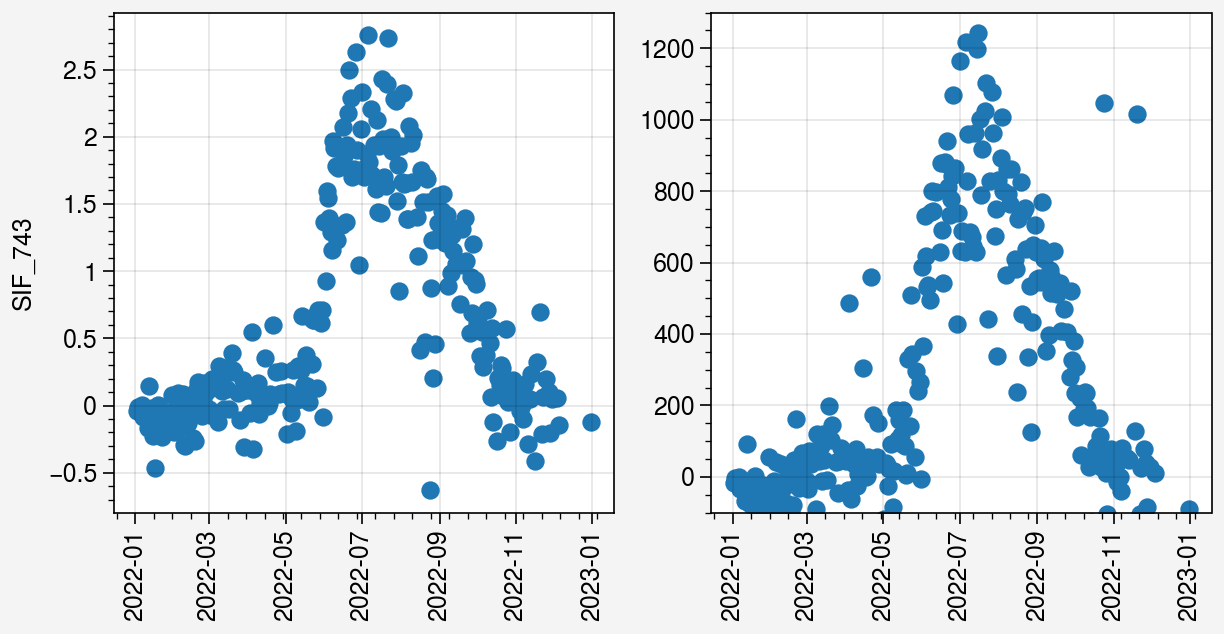

In [24]:
fig, axes = uplt.subplots(ncols = 2, sharey=False)
axes[0].scatter(test_year.index, test_year['SIF_743'], label='SIF_743')
axes[1].scatter(test_year.index, test_year['SIF_743']/test_year['adjust_factor'], label='SIF_743')
axes[1].format(ylim=(-100, 1300))